In [2]:
# Exploratory Data Analysis (EDA) on Microsoft Stock Data

In [9]:
'''
Dataset Overview
This dataset contains daily stock price and volume data for Microsoft (MSFT) from its IPO on March 13, 1986 through August 1989. The data includes:

Date

Open price

High price

Low price

Close price

Adjusted close price

Trading volume
'''

'\nDataset Overview\nThis dataset contains daily stock price and volume data for Microsoft (MSFT) from its IPO on March 13, 1986 through August 1989. The data includes:\n\nDate\n\nOpen price\n\nHigh price\n\nLow price\n\nClose price\n\nAdjusted close price\n\nTrading volume\n'

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# loading the dataset 

In [9]:
df = pd.read_csv('MSFT_daily_data.csv')
df.head()

,Date,Open,High,Low,Close,Adj Close,Volume
0,1986-03-13,0.088542,0.101563,0.088542,0.097222,0.059946,1031788800
1,1986-03-14,0.097222,0.102431,0.097222,0.100694,0.062087,308160000
2,1986-03-17,0.100694,0.103299,0.100694,0.102431,0.063158,133171200
3,1986-03-18,0.102431,0.103299,0.098958,0.099826,0.061552,67766400
4,1986-03-19,0.099826,0.100694,0.097222,0.098090,0.060482,47894400


In [11]:
# Database Structure 

In [13]:
# Shape of the dataset
print("Shape:", df.shape)

# Column names and data types
print(df.info())

# Statistical summary
df.describe()


Shape: (9737, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9737 entries, 0 to 9736
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Date       9737 non-null   object 
 1   Open       9737 non-null   float64
 2   High       9737 non-null   float64
 3   Low        9737 non-null   float64
 4   Close      9737 non-null   float64
 5   Adj Close  9737 non-null   float64
 6   Volume     9737 non-null   int64  
dtypes: float64(5), int64(1), object(1)
memory usage: 532.6+ KB
None


,Open,High,Low,Close,Adj Close,Volume
count,9737.000000,9737.000000,9737.000000,9737.000000,9737.000000,9.737000e+03
mean,60.813783,61.430055,60.172971,60.823922,55.162815,5.652701e+07
std,94.519709,95.369718,93.588185,94.522300,94.588374,3.814013e+07
min,0.088542,0.092014,0.088542,0.090278,0.055665,2.304000e+06
25%,5.789063,5.867188,5.695313,5.789063,3.569499,3.169170e+07
50%,27.360001,27.709999,27.150000,27.400000,19.218304,4.968890e+07
75%,47.099998,47.599998,46.529999,47.110001,39.407841,7.043040e+07
max,467.000000,468.350006,464.459991,467.559998,466.718781,1.031789e+09


In [15]:
# Check for Missing Values

In [17]:
df.isnull().sum()


Date         0
Open         0
High         0
Low          0
Close        0
Adj Close    0
Volume       0
dtype: int64

In [19]:
# Rename Columns (if needed)
# Sometimes column names may contain spaces or inconsistent naming.

In [21]:
df.columns = df.columns.str.strip().str.lower().str.replace(' ', '_')


In [23]:
# Check for Duplicates

In [25]:
df.duplicated().sum()


0

In [27]:
# Date Handling 
# Check if there's a date column and convert it.

In [29]:
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date')
df.set_index('date', inplace=True)


In [33]:
df

,open,high,low,close,adj_close,volume
date,,,,,,
1986-03-13,0.088542,0.101563,0.088542,0.097222,0.059946,1031788800
1986-03-14,0.097222,0.102431,0.097222,0.100694,0.062087,308160000
1986-03-17,0.100694,0.103299,0.100694,0.102431,0.063158,133171200
1986-03-18,0.102431,0.103299,0.098958,0.099826,0.061552,67766400
1986-03-19,0.099826,0.100694,0.097222,0.098090,0.060482,47894400
...,...,...,...,...,...,...
2024-10-24,425.329987,425.980011,422.399994,424.730011,424.730011,13581600
2024-10-25,426.760010,432.519989,426.570007,428.149994,428.149994,16899100
2024-10-28,431.660004,431.940002,426.299988,426.589996,426.589996,14882400


In [39]:
# Plotting Time Series Data
# Visualize Trends Over Time - To spot long-term trends in the data such as whether the stock price is generally increasing, decreasing, or staying flat.
# Detect Seasonality or Cycles - ome patterns repeat over time daily, weekly, monthly, or yearly. Plotting helps reveal these seasonal behaviors or cycles.
# Identify Volatility and Anomalies - To spot spikes, drops, or abnormal behavior that might signal important events, errors, or outliers.
# Understand Data Continuity and Frequency - To verify whether your time series is continuous (no missing dates) and whether the data frequency is consistent (e.g., daily, weekly).
# Compare Actual vs Derived Metrics - By plotting original values (e.g., closing price) alongside calculated metrics (like moving averages), to compare trends and smooth out noise.

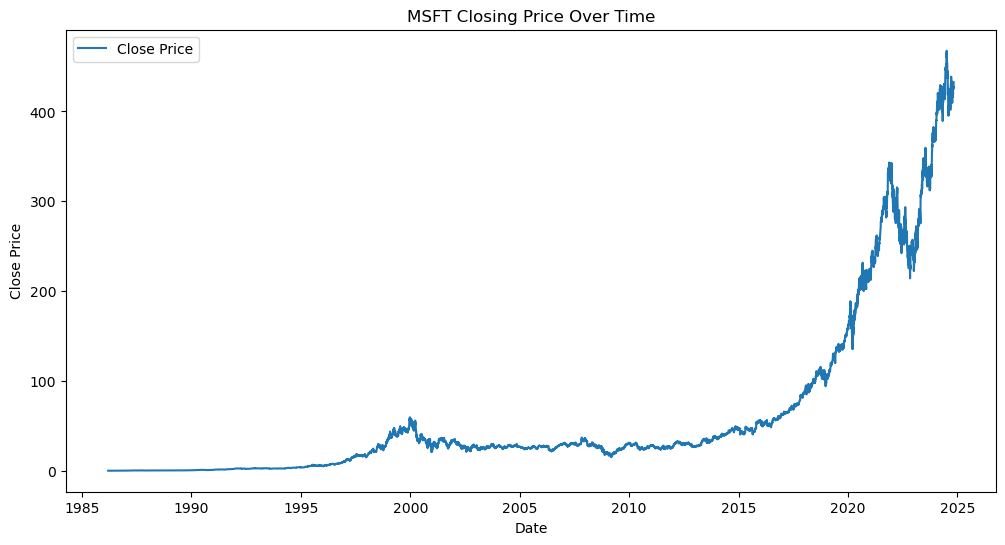

In [41]:
plt.figure(figsize=(12,6))
plt.plot(df['close'], label='Close Price')
plt.title('MSFT Closing Price Over Time')
plt.xlabel('Date')
plt.ylabel('Close Price')
plt.legend()
plt.show()


In [43]:
# Correlation Heatmap

In [45]:
'''
Plotting a correlation heatmap is an essential part of Exploratory Data Analysis (EDA), 
especially when  working with datasets that contain multiple numerical variables, 
like stock prices, volumes, and indicators.
'''

'\nPlotting a correlation heatmap is an essential part of Exploratory Data Analysis (EDA), \nespecially when  working with datasets that contain multiple numerical variables, \nlike stock prices, volumes, and indicators.\n'

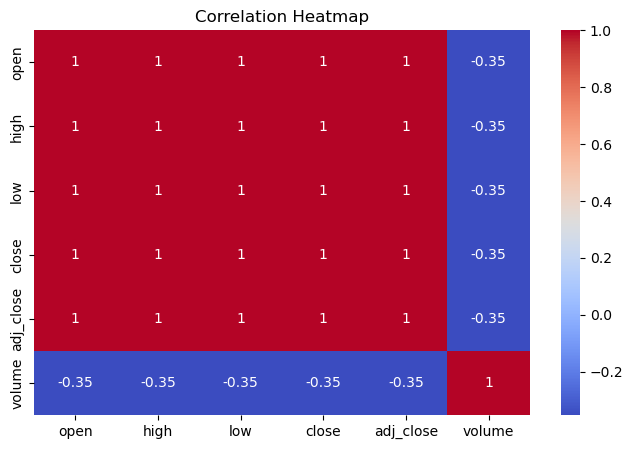

In [47]:
plt.figure(figsize=(8,5))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm')
plt.title("Correlation Heatmap")
plt.show()


In [49]:
 ''' What This Represents Visually
A color-coded grid (matrix) where:

Each cell compares two variables (e.g., open vs close, close vs volume, etc.).

The color of the cell tells you the strength and direction of the correlation.

The number in the cell is the actual correlation value, from -1 to +1.'''

' What This Represents Visually\nA color-coded grid (matrix) where:\n\nEach cell compares two variables (e.g., open vs close, close vs volume, etc.).\n\nThe color of the cell tells you the strength and direction of the correlation.\n\nThe number in the cell is the actual correlation value, from -1 to +1.'

In [51]:
'''
Real-World Use Case in Stock Data
Dataset has columns like open, high, low, close, and volume.

If close and open have high positive correlation (~0.95):

It means they move almost together in stock data.

If close and volume show low correlation (~0.2 or -0.1):

Price and trading volume are not strongly related in a linear way.
'''

'\nReal-World Use Case in Stock Data\nDataset has columns like open, high, low, close, and volume.\n\nIf close and open have high positive correlation (~0.95):\n\nIt means they move almost together in stock data.\n\nIf close and volume show low correlation (~0.2 or -0.1):\n\nPrice and trading volume are not strongly related in a linear way.\n'

In [53]:
# Moving Averages

In [55]:
# Purpose of Moving Averages

# Smooth Out Short-Term Fluctuations - 
# Stock prices often show random ups and downs. Moving averages help to reduce volatility and make long-term trends clearer.

#Identify Trends
#They help determine if a stock is in an uptrend, downtrend, or sideways movement.
#Uptrend: Price stays above the moving average
#Downtrend: Price stays below the moving average



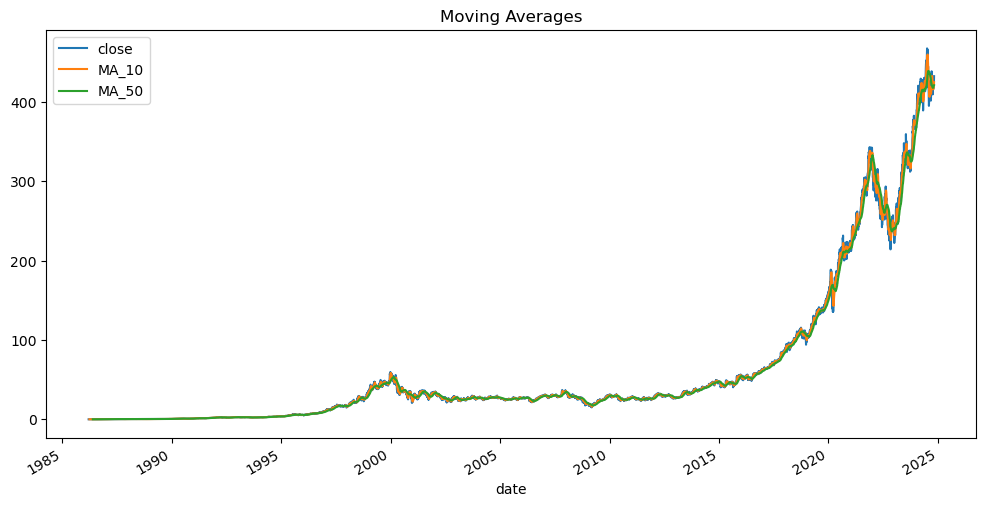

In [57]:
df['MA_10'] = df['close'].rolling(window=10).mean()
df['MA_50'] = df['close'].rolling(window=50).mean()

df[['close', 'MA_10', 'MA_50']].plot(figsize=(12,6))
plt.title('Moving Averages')
plt.show()


In [59]:
# Daily Returns Analysis

In [63]:
'''
Purpose of Daily Returns Analysis - 

Measure Stock Performance:
Daily returns tell you how much a stock’s price has changed from one day to the next — as a percentage.

Assess Risk and Volatility:
By plotting or analyzing daily returns, you can quantify the volatility of a stock — i.e., how much and how often the price swings.

Return Distribution Analysis:
You can create histograms of daily returns to understand the distribution of gains vs losses.

Compare Assets:
Daily returns allow for direct comparison between different stocks or portfolios, even if their prices are on different scales.
'''

'\nPurpose of Daily Returns Analysis - \n\nMeasure Stock Performance:\nDaily returns tell you how much a stock’s price has changed from one day to the next — as a percentage.\n\nAssess Risk and Volatility:\nBy plotting or analyzing daily returns, you can quantify the volatility of a stock — i.e., how much and how often the price swings.\n\nReturn Distribution Analysis:\nYou can create histograms of daily returns to understand the distribution of gains vs losses.\n\nCompare Assets:\nDaily returns allow for direct comparison between different stocks or portfolios, even if their prices are on different scales.\n'

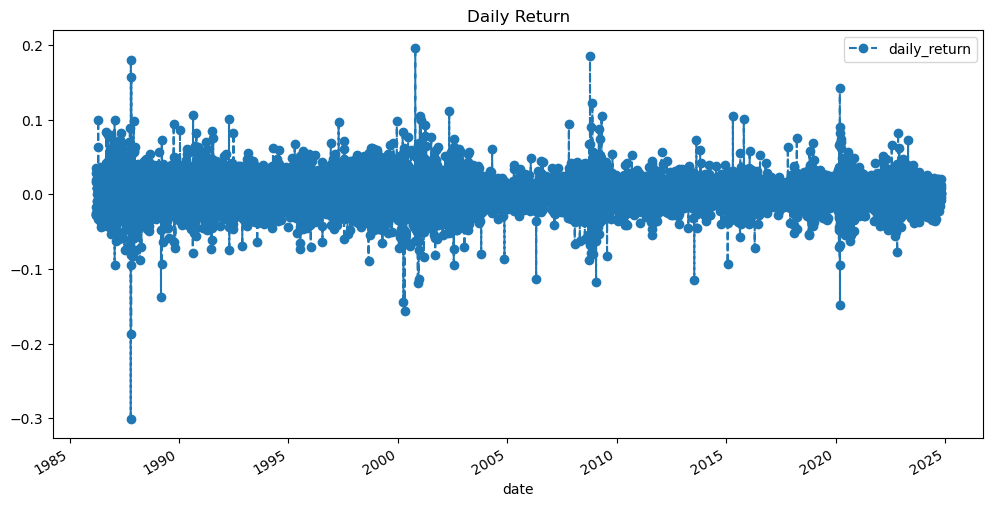

In [65]:
df['daily_return'] = df['close'].pct_change()
df['daily_return'].plot(figsize=(12,6), legend=True, linestyle='--', marker='o', title='Daily Return')
plt.show()


In [71]:
'''
This line plots the daily return over time using Matplotlib and Pandas plotting functionality.

figsize=(12,6) makes the plot large and readable.

legend=True displays the legend with label 'daily_return'.

linestyle='--' creates a dashed line to connect the data points.

marker='o' adds a circular dot at each data point.

title='Daily Return' gives a title to the chart.

plt.show() renders the plot in the output cell.
'''

"\nThis line plots the daily return over time using Matplotlib and Pandas plotting functionality.\n\nfigsize=(12,6) makes the plot large and readable.\n\nlegend=True displays the legend with label 'daily_return'.\n\nlinestyle='--' creates a dashed line to connect the data points.\n\nmarker='o' adds a circular dot at each data point.\n\ntitle='Daily Return' gives a title to the chart.\n\nplt.show() renders the plot in the output cell.\n"

In [73]:
'''
Interpretation:

Above 0 = the stock price went up that day

Below 0 = the stock price went down

High spikes = big gains or losses (volatility)

Flat or near-zero lines = stability
'''

'\nInterpretation:\n\nAbove 0 = the stock price went up that day\n\nBelow 0 = the stock price went down\n\nHigh spikes = big gains or losses (volatility)\n\nFlat or near-zero lines = stability\n'

In [75]:
# use case :

# Helps visualize volatility and market behavior

# Identify outliers or shock events (like earnings reports, market crashes)

# Understand how risky or stable the stock is on a daily basis

In [77]:
# Histogram of Returns

In [81]:
'''
Purpose of Histogram of Returns:

Understand the Distribution of Daily Returns-
A histogram shows how often each range of daily returns occurs.

Visualize Risk and Volatility-
A wider spread of the histogram = higher volatility (more risk)
A narrower spread = more stable stock
'''

'\nPurpose of Histogram of Returns:\n\nUnderstand the Distribution of Daily Returns-\nA histogram shows how often each range of daily returns occurs.\n\nVisualize Risk and Volatility-\nA wider spread of the histogram = higher volatility (more risk)\nA narrower spread = more stable stock\n'

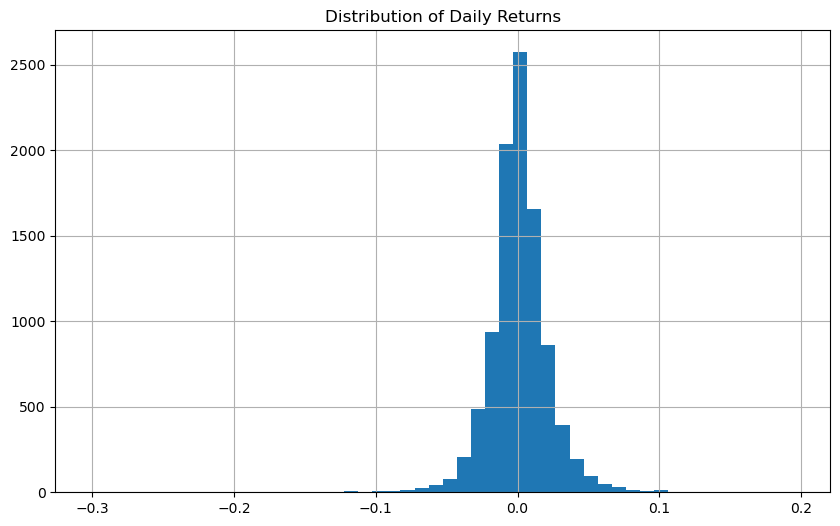

In [89]:
df['daily_return'].hist(bins=50, figsize=(10,6))
plt.title('Distribution of Daily Returns')
plt.show()

In [85]:
'''
What the Plot Represents
X-axis = Daily return percentages (positive and negative)

Y-axis = How often (frequency) each return value occurred
'''

'\nWhat the Plot Represents\nX-axis = Daily return percentages (positive and negative)\n\nY-axis = How often (frequency) each return value occurred\n'

In [ ]:
'''
Interpretation
Peak in the center: Most returns are small, close to 0 = normal trading days.

Tails on both sides: Occasional big gains or losses.

Symmetry: If it’s fairly symmetrical, it means gains and losses are equally likely.

Fat tails: If the ends are high, it means more extreme events happen than in a normal distribution
'''